# Aprendizado Não Supervisionado — Aula Prática

**Objetivo:** entender o que é aprendizado não supervisionado, o que é clusterização,
e aplicar isso de ponta a ponta em um problema real: exploração, EDA, treinamento de
múltiplos algoritmos (clássicos + deep learning) e interpretação dos resultados.

**Dataset:** `digits` (NIST) — 1.797 imagens 8×8 de dígitos manuscritos, 64 features.
É um benchmark canônico de clusterização: tem estrutura real, alta dimensionalidade,
10 grupos naturais e rótulos verdadeiros disponíveis **apenas para validação**.

**Sumário**
1. O que é aprendizado não supervisionado
2. Importância e aplicações
3. O que é clusterização
4. Como avaliar clusters
5. O problema e os dados
6. EDA
7. Pré-processamento e redução de dimensionalidade
8. K-Means a fundo
9. Bateria de modelos clássicos
10. Deep Learning: Autoencoder, VAE e Deep Embedded Clustering
11. Visualização e interpretação
12. Boas práticas, erros comuns e exercícios

In [1]:
import sys, os, time, random, warnings
warnings.filterwarnings("ignore")
os.environ.setdefault("LOKY_MAX_CPU_COUNT", str(os.cpu_count() or 4))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn import datasets
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.neighbors import NearestNeighbors
from sklearn.cluster import (KMeans, MiniBatchKMeans, DBSCAN, OPTICS, Birch,
                             AgglomerativeClustering, MeanShift,
                             SpectralClustering, AffinityPropagation)
from sklearn.mixture import GaussianMixture
from sklearn.metrics import (silhouette_score, davies_bouldin_score,
                             calinski_harabasz_score, adjusted_rand_score,
                             normalized_mutual_info_score)

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset
from joblib import parallel_backend

SEED = 42
np.random.seed(SEED); random.seed(SEED); torch.manual_seed(SEED)
torch.backends.cudnn.benchmark = True

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 110

print(f"Python       : {sys.version.split()[0]}")
print(f"NumPy        : {np.__version__}")
print(f"pandas       : {pd.__version__}")
print(f"scikit-learn : {__import__('sklearn').__version__}")
print(f"PyTorch      : {torch.__version__}")
print(f"Device       : {DEVICE}")

if DEVICE.type == "cuda":
    props = torch.cuda.get_device_properties(0)
    print(f"GPU          : {torch.cuda.get_device_name(0)}")
    print(f"VRAM         : {props.total_memory / 1e9:.1f} GB")
    print(f"CUDA runtime : {torch.version.cuda}")
else:
    print("\nCUDA não detectada. O notebook roda igual em CPU — apenas mais devagar.")
    print("Para habilitar GPU: instale o PyTorch com CUDA e verifique com torch.cuda.is_available().")

Python       : 3.11.9
NumPy        : 1.26.4
pandas       : 2.1.4
scikit-learn : 1.4.2
PyTorch      : 2.5.1+cu121
Device       : cuda
GPU          : NVIDIA GeForce GTX 1660 Ti
VRAM         : 6.4 GB
CUDA runtime : 12.1


## 1. O que é Aprendizado Não Supervisionado

Aprendizado não supervisionado é o ramo do Machine Learning em que o modelo aprende
a **estrutura dos dados sem rótulos**. Não existe "resposta certa" fornecida: o
algoritmo descobre padrões por conta própria.

Formalmente, dado um conjunto de exemplos $X = \{x_1, x_2, \dots, x_n\}$, cada
$x_i \in \mathbb{R}^d$, o objetivo é encontrar uma representação, uma partição ou
uma função de densidade $f$ que descreva a estrutura de $X$ sem usar $y$.

### Comparação direta

| Aspecto | Supervisionado | Não supervisionado |
|---|---|---|
| Entrada | $X$ **e** rótulos $y$ | Apenas $X$ |
| Objetivo | Prever $y$ para novos $x$ | Descobrir estrutura em $X$ |
| Métrica | Acurácia, F1, RMSE | Silhueta, Davies-Bouldin, ARI, BIC |
| Risco típico | Overfitting | Interpretação ambígua de clusters |
| Exemplo | "Este e-mail é spam?" | "Quais grupos naturais existem?" |

### Os cinco grandes problemas não supervisionados

1. **Clusterização** — agrupar objetos similares. É o foco desta aula.
2. **Redução de dimensionalidade** — comprimir $d$ mantendo a informação essencial
   (PCA, t-SNE, UMAP, autoencoders).
3. **Detecção de anomalias** — encontrar o que não segue o padrão dominante
   (Isolation Forest, LOF, One-Class SVM).
4. **Associação** — descobrir regras de coocorrência (Apriori, cesta de compras).
5. **Modelos generativos** — aprender a distribuição $P(X)$ para gerar novos dados
   (VAE, GAN, difusão).

> **Ponto-chave:** redução de dimensionalidade e clusterização costumam andar juntas.
> Reduzir dimensão antes de agrupar é uma das práticas mais eficazes — e você vai
> ver isso funcionar na prática mais adiante.

## 2. Por que isso é importante

A maior parte dos dados do mundo **não tem rótulo**. Rotular é caro, lento e exige
especialista. Um projeto típico de ciência de dados segue:

> 1. Explorar sem supervisão → 2. Descobrir estrutura → 3. Rotular as descobertas
> → 4. Só então treinar um modelo supervisionado.

O não supervisionado é, na prática, a **etapa de descoberta**.

### Onde aparece no mundo real

- **Varejo / CRM** — segmentação de clientes por comportamento de compra (RFM),
  para campanhas direcionadas em vez de disparo em massa.
- **Finanças** — detecção de transações atípicas; agrupamento de perfis de risco.
- **Manufatura** — manutenção preditiva: agrupar assinaturas de sensores e detectar
  o padrão que desvia do normal.
- **Saúde** — descoberta de subtipos de pacientes a partir de exames, sem diagnóstico
  prévio; agrupamento de imagens médicas.
- **NLP** — embeddings de palavras/frases, *topic modeling* (LDA, BERTopic).
- **Visão computacional** — segmentação de imagens, agrupamento de rostos.
- **Cibersegurança** — *threat hunting*: encontrar comportamento anômalo sem assinatura.
- **Bioinformática** — agrupamento de genes com expressão similar.

### Limitações que você precisa ter em mente

- **Não há "verdade absoluta"**: um cluster é uma construção do algoritmo, não um
  fato da natureza. Algoritmos diferentes encontram partições diferentes — todas
  potencialmente válidas.
- **Escala importa**: K-Means em dados não normalizados é praticamente garantia de
  resultado ruim.
- **Sensibilidade a hiperparâmetros**: o número de clusters, o `eps` do DBSCAN,
  a banda do MeanShift — tudo muda o resultado.
- **Interpretação é trabalho humano**: o algoritmo entrega grupos; o analista
  entrega significado.

## 3. O que é Clusterização

Clusterizar é **particionar um conjunto de objetos em grupos de modo que os objetos
dentro de um grupo sejam mais parecidos entre si do que com os objetos de fora**.

Tudo depende de uma decisão fundamental: **o que significa "parecido"?**

### 3.1 Similaridade e distância

| Distância | Fórmula | Quando usar |
|---|---|---|
| Euclidiana ($L_2$) | $\sqrt{\sum_i (a_i - b_i)^2}$ | Dados contínuos, escalas comparáveis |
| Manhattan ($L_1$) | $\sum_i \|a_i - b_i\|$ | Robustez a outliers, dados esparsos |
| Cosseno | $1 - \frac{a \cdot b}{\|a\|\|b\|}$ | Texto, embeddings, alta dimensionalidade |
| Cidade/quadrada | $L_2^2$ | Otimização de K-Means (matematicamente) |

> Normalize os dados **antes** de calcular distâncias. Uma feature em reais e outra
> em porcentagem dominam a métrica injustamente se ficarem em escalas diferentes.

### 3.2 As seis famílias de algoritmos

1. **Baseados em centróide** — K-Means, MiniBatchKMeans. Rápidos, assumem clusters
   convexos e de tamanho similar.
2. **Baseados em densidade** — DBSCAN, HDBSCAN, OPTICS. Encontram formas arbitrárias
   e detectam ruído. Não exigem informar $k$.
3. **Hierárquicos** — Agglomerative, Birch. Produzem dendrograma; você "corta" na
   altura desejada.
4. **Probabilísticos** — Gaussian Mixture Models. Clusters "suaves": cada ponto tem
   probabilidade de pertencer a cada grupo. Permitem clusters elípticos.
5. **Baseados em grafo** — Spectral Clustering. Excelente em estruturas não convexas.
6. **Neurais** — Autoencoders, VAE, DEC, redes contrastivas. Aprendem representação
   e agrupamento conjuntamente.

### 3.3 O problema central (e por que é difícil)

Clusterizar bem exige resolver duas coisas ao mesmo tempo:

1. **Qual é a representação certa dos dados?** (features, escala, dimensão)
2. **Qual é a partição certa?**

O problema é **circular**: para agrupar bem você precisa de uma boa representação, e
para avaliar a representação você precisa agrupar. É exatamente essa circularidade
que o deep learning ataca de frente — ele **aprende a representação e a partição
simultaneamente**. Guarde isso, é o fio condutor da segunda metade da aula.

### 3.4 Hard vs Soft clustering

- **Hard** (K-Means, DBSCAN, hierárquico): cada ponto pertence a exatamente um cluster.
- **Soft / fuzzy** (GMM, Fuzzy C-Means, DEC): cada ponto tem um vetor de
  probabilidades de pertencer a cada cluster.

Soft clustering é preferível quando os grupos se sobrepõem — o que, em dados reais,
é a regra, não a exceção.

### 3.5 Como avaliar clusters sem rótulos

Esse é o ponto onde a maioria trava. Existem três famílias de métricas:

**a) Métricas internas** (não usam rótulo verdadeiro — medem coesão e separação)

- **Silhouette** (de −1 a 1): $\frac{b - a}{\max(a,b)}$, onde $a$ = distância média
  intra-cluster e $b$ = distância média ao cluster vizinho mais próximo. Quanto
  mais perto de 1, melhor. **A melhor métrica geral para uso diário.**
- **Davies-Bouldin**: razão entre dispersão intra e separação inter. **Menor é melhor**.
  Mínimo teórico 0.
- **Calinski-Harabasz**: razão variância entre/média. **Maior é melhor**. Favorece
  clusters esféricos.

**b) Métricas externas** (comparar com rótulo conhecido — usadas só para validar
o método em um dataset de estudo, nunca em produção)

- **ARI** (Adjusted Rand Index): concordância entre duas partições, corrigida por
  acaso. 1 = idênticas, 0 = aleatório.
- **NMI**: informação mútua normalizada. Vai de 0 a 1.

**c) Métricas de informação do modelo**

- **Inércia** (K-Means): soma das distâncias ao quadrado até o centróide. Sempre
  cai quando você aumenta $k$ — por isso se usa o *elbow method*.
- **BIC / AIC** (GMM): penalizam complexidade. Permitem escolher o número de
  componentes de forma objetiva.

> **Na prática:** use uma métrica interna para decidir e uma externa para validar.
> Se as duas concordarem, você tem confiança no resultado. Neste notebook usaremos
> ARI e NMI com os rótulos verdadeiros **apenas como réguas de validação** — como o
> algoritmo nunca os vê, continua sendo 100% não supervisionado.

### 3.5 Como avaliar clusters sem rótulos

Esse é o ponto onde a maioria trava. Existem três famílias de métricas:

**a) Métricas internas** (não usam rótulo verdadeiro — medem coesão e separação)

- **Silhouette** (de −1 a 1): $\frac{b - a}{\max(a,b)}$, onde $a$ = distância média
  intra-cluster e $b$ = distância média ao cluster vizinho mais próximo. Quanto
  mais perto de 1, melhor. **A melhor métrica geral para uso diário.**
- **Davies-Bouldin**: razão entre dispersão intra e separação inter. **Menor é melhor**.
  Mínimo teórico 0.
- **Calinski-Harabasz**: razão variância entre/média. **Maior é melhor**. Favorece
  clusters esféricos.

**b) Métricas externas** (comparar com rótulo conhecido — usadas só para validar
o método em um dataset de estudo, nunca em produção)

- **ARI** (Adjusted Rand Index): concordância entre duas partições, corrigida por
  acaso. 1 = idênticas, 0 = aleatório.
- **NMI**: informação mútua normalizada. Vai de 0 a 1.

**c) Métricas de informação do modelo**

- **Inércia** (K-Means): soma das distâncias ao quadrado até o centróide. Sempre
  cai quando você aumenta $k$ — por isso se usa o *elbow method*.
- **BIC / AIC** (GMM): penalizam complexidade. Permitem escolher o número de
  componentes de forma objetiva.

> **Na prática:** use uma métrica interna para decidir e uma externa para validar.
> Se as duas concordarem, você tem confiança no resultado. Neste notebook usaremos
> ARI e NMI com os rótulos verdadeiros **apenas como réguas de validação** — como o
> algoritmo nunca os vê, continua sendo 100% não supervisionado.

# PCA — Análise de Componentes Principais

## 1. O que é

A **Análise de Componentes Principais** (*Principal Component Analysis*, PCA) é uma
técnica de **redução de dimensionalidade linear** que transforma um conjunto de
variáveis correlacionadas em um conjunto menor de variáveis **não correlacionadas**,
chamadas **componentes principais**, ordenadas pela quantidade de variância que
explicam.

Em uma frase: **o PCA encontra as direções em que os dados mais variam e projeta os
dados nessas direções.**

Formalmente, dado uma matriz de dados $X \in \mathbb{R}^{n \times d}$ com $n$ amostras
e $d$ features, o PCA busca uma transformação linear para um espaço de dimensão
$k < d$ que preserve o máximo possível da variância original.

> O PCA **não usa rótulos**. É aprendizado não supervisionado puro. Ele não sabe
> "o que é" cada grupo — apenas descreve a geometria dos dados.

---

## 2. A intuição geométrica (o que realmente acontece)

Imagine uma nuvem de pontos em 3D, achatada como um charuto inclinado:

1. **Primeira componente (PC1)** — é o eixo ao longo do comprimento do charuto.
   É a direção de **maior variância** dos dados. Se você tivesse que escolher uma
   única reta para representar os pontos, seria essa.
2. **Segunda componente (PC2)** — é perpendicular à primeira e aponta para a
   segunda direção de maior variância. No caso do charuto, é sua largura.
3. **Terceira componente (PC3)** — perpendicular às duas anteriores. No charuto,
   é a espessura, que é quase zero.

O PCA **gira o sistema de coordenadas** para alinhá-lo com a forma natural da nuvem
de dados. As novas coordenadas são combinações lineares das antigas.

Se a PC3 explica apenas 0,5% da variância, você pode descartá-la e representar o
charuto em 2D perdendo quase nada. **É isso que o PCA faz: descarta as direções
"finas" e mantém as "gordas".**

### Duas leituras equivalentes do mesmo método

- **Maximizar variância:** a primeira componente é a direção $w$ que maximiza
  $\text{Var}(Xw)$, sujeita a $\|w\| = 1$.
- **Minimizar erro de reconstrução:** a primeira componente é a reta que minimiza a
  soma dos quadrados das distâncias dos pontos até ela (o "erro de projeção").

Matematicamente, as duas formulações têm **a mesma solução**. Isso é uma
propriedade elegante: preservar a variância é o mesmo que perder o mínimo de
informação geométrica.

---

## 3. A matemática (sem mistério)

### 3.1 Passo 1 — Centralizar os dados

O PCA exige que os dados tenham média zero. Caso contrário, a "direção de maior
variância" seria simplesmente a direção que aponta do zero até a média dos dados —
um artefato, não estrutura.

$$X_c = X - \bar{X}$$

onde $\bar{X}$ é o vetor de médias de cada feature.

### 3.2 Passo 2 — A matriz de covariância

A covariância captura como duas features variam juntas:

$$\Sigma = \frac{1}{n-1} X_c^\top X_c$$

A matriz $\Sigma$ é $d \times d$, simétrica e positiva semidefinida. A diagonal
contém as variâncias de cada feature; fora da diagonal, as covariâncias entre pares.

### 3.3 Passo 3 — Autovalores e autovetores

Decompomos a matriz de covariância:

$$\Sigma v_i = \lambda_i v_i$$

- **Autovetores** $v_i$ → as **direções** das componentes principais.
- **Autovalores** $\lambda_i$ → a **quantidade de variância** explicada por cada
  direção.

Ordenando os autovalores em ordem decrescente ($\lambda_1 \geq \lambda_2 \geq \dots
\geq \lambda_d$), os autovetores correspondentes são as componentes, da mais
informativa para a menos.

> Autovetores de uma matriz simétrica são **ortogonais entre si**. É por isso que
> as componentes principais são sempre **não correlacionadas** — o PCA diagonaliza
> a estrutura de covariância.

### 3.4 Passo 4 — Projetar os dados

Para reduzir de $d$ para $k$ dimensões, montamos a matriz $W_k$ com os $k$ primeiros
autovetores como colunas e projetamos:

$$Z = X_c W_k$$

O resultado $Z \in \mathbb{R}^{n \times k}$ é o conjunto de dados transformado.

### 3.5 A variância explicada

A fração de variância explicada pela componente $i$ é simplesmente:

$$\text{VE}_i = \frac{\lambda_i}{\sum_{j=1}^{d} \lambda_j}$$

E a variância acumulada nas primeiras $k$ componentes:

$$\text{VE acumulada}(k) = \frac{\sum_{i=1}^{k} \lambda_i}{\sum_{j=1}^{d} \lambda_j}$$

Essa é a métrica que você usa para decidir quantas componentes manter.

### 3.6 SVD — como é calculado na prática

Ninguém calcula a matriz de covariância e a decompõe em produção: é numericamente
instável e lento. A implementação real usa **Decomposição em Valores Singulares**
(SVD) da matriz centralizada:

$$X_c = U S V^\top$$

Os autovetores de $\Sigma$ são as colunas de $V$, e os autovalores são
$\lambda_i = s_i^2 / (n-1)$. O resultado é o mesmo, mas com estabilidade numérica
muito superior — e é exatamente o que o `sklearn` e o `numpy` fazem por baixo.

---

## 4. Para que serve — os seis usos reais

### 4.1 Redução de dimensionalidade

O uso central. Passar de 500 features para 30 componentes pode reduzir tempo de
treino em ordens de magnitude com perda mínima de informação. É a aplicação mais
comum em pipelines de machine learning com muitas variáveis correlacionadas.

### 4.2 Visualização de dados de alta dimensão

Não é possível desenhar 64 dimensões. Projetar em 2D com PCA é a forma mais rápida
de ter um primeiro olhar sobre a estrutura dos dados. A projeção é **linear**, então
o que aparece no gráfico é uma visão parcial — mas honesta — da geometria real.

> Para visualização, o t-SNE e o UMAP costumam separar melhor os grupos. A vantagem
> do PCA aqui é ser instantâneo, determinístico e reprodutível.

### 4.3 Remoção de ruído

As últimas componentes tendem a capturar quase só ruído (variância aleatória de
baixa amplitude). Descartá-las é uma forma de **filtro**: você reconstrói os dados
usando apenas as $k$ primeiras componentes e obtém uma versão suavizada da realidade.

$$X_{\text{reconstruído}} = Z W_k^\top + \bar{X}$$

### 4.4 Descorrelação (pré-processamento)

Modelos como regressão linear múltipla sofrem com **multicolinearidade** — features
muito correlacionadas tornam os coeficientes instáveis. Como as componentes do PCA
são ortogonais por construção, usar $Z$ em vez de $X$ elimina esse problema
estruturalmente.

### 4.5 Aceleração de clusterização e KNN

Algoritmos baseados em distância se degradam em alta dimensionalidade (*maldição da
dimensionalidade*: as distâncias tendem a se uniformizar). Reduzir com PCA antes de
rodar K-Means, DBSCAN ou KNN melhora tanto a velocidade quanto a qualidade do
resultado. É a combinação que usamos no notebook de aprendizado não supervisionado.

### 4.6 Compressão e extração de features

Em imagens, sinais e séries temporais, o PCA funciona como um codec linear: guarda
$k$ coeficientes por amostra em vez de $d$ valores brutos. Em *eigenfaces*, rostos
são representados por dezenas de componentes em vez de milhares de pixels.

---

## 5. Como escolher o número de componentes

Não existe regra universal, mas existem quatro critérios objetivos:

| Critério | Regra prática | Quando usar |
|---|---|---|
| **Variância acumulada** | Manter 90–95% | Padrão de mercado para pré-processamento |
| **Kaiser** | Manter componentes com $\lambda_i > 1$ (dados padronizados) | Quando as features estão em escala comparável |
| **Scree plot** | Cortar no "cotovelo" da curva de autovalores | Análise exploratória |
| **Validação a jusante** | Otimizar a métrica do modelo final | Quando o PCA é etapa de um pipeline supervisionado |

> **Regra de ouro:** o número de componentes não é um fim em si. Se o objetivo é
> visualizar, use 2. Se o objetivo é alimentar um modelo, escolha $k$ pela métrica
> final, não pela variância.

---

## 6. Limitações — o que você precisa saber antes de usar

**a) É estritamente linear.** O PCA só encontra estruturas planas. Se os dados
formam uma variedade curva (um "S" em 3D, uma circunferência), a projeção linear
vai destruir a estrutura. Para isso existem t-SNE, UMAP, Isomap, autoencoders.

**b) Assume que variância = informação.** O PCA trata direções de alta variância
como importantes. Mas uma feature pode ter variância enorme e ser **puro ruído**
(ex.: um sensor descalibrado). Nesse caso, o PCA vai dar a ela a primeira componente.
Sempre inspecione os dados antes.

**c) É sensível à escala.** Uma feature em reais (milhares) e outra em porcentagem
(0–100) fazem o PCA apontar quase inteiramente para a primeira. **Padronize com
`StandardScaler` antes** — a menos que você queira deliberadamente preservar as
escalas originais.

**d) É sensível a outliers.** A média e a variância são estatísticas não robustas.
Um único ponto extremo pode girar toda a primeira componente. Alternativas:
`RobustScaler`, ou remoção de outliers antes do ajuste.

**e) As componentes perdem interpretabilidade.** PC1 é uma combinação linear de
todas as features originais com coeficientes arbitrários. Dizer "PC1 representa
'saúde financeira'" exige análise dos *loadings* e é sempre uma interpretação
humana, nunca um fato do método.

**f) Componentes não são features.** Você não pode dizer "o cliente tem PC2 = 3,4".
As componentes vivem em um espaço abstrato construído para maximizar variância.

---

## 7. PCA vs. as alternativas

| Método | Tipo | Preserva | Velocidade | Uso típico |
|---|---|---|---|---|
| **PCA** | Linear | Variância global | Muito rápido | Pré-processamento, compressão |
| **t-SNE** | Não linear | Vizinhança local | Lento | Visualização 2D |
| **UMAP** | Não linear | Estrutura local + global | Rápido | Visualização e features |
| **Autoencoder** | Não linear | Reconstrução | Depende de GPU | Alta dimensionalidade complexa |
| **ICA** | Linear | Independência estatística | Rápido | Separação de sinais (áudio, EEG) |
| **LDA** | Linear supervisionado | Separabilidade entre classes | Rápido | Redução com rótulos disponíveis |
| **TruncatedSVD** | Linear | Variância em matrizes esparsas | Rápido | Texto (TF-IDF), dados esparsos |

**Regra de decisão:** comece sempre pelo PCA. É rápido, determinístico, barato e
resolve a maioria dos casos. Só migre para métodos não lineares quando o PCA
visivelmente falhar em preservar a estrutura — e saiba que essa migração custa
tempo, hiperparâmetros e reprodutibilidade.

---

## 8. Implementação prática

```python
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# 1. Padronizar (obrigatório)
X_std = StandardScaler().fit_transform(X)

# 2. Ajustar com todas as componentes para inspecionar a variância
pca_full = PCA(random_state=42).fit(X_std)
var_acum = np.cumsum(pca_full.explained_variance_ratio_)

n90 = int(np.argmax(var_acum >= 0.90) + 1)
print(f"Componentes para 90% da variância: {n90} de {X.shape[1]}")

# 3. Reduzir de fato
pca = PCA(n_components=n90, random_state=42)
X_pca = pca.fit_transform(X_std)

# 4. Reconstruir (útil para medir perda e filtrar ruído)
X_rec = pca.inverse_transform(X_pca)

print(f"Shape original     : {X_std.shape}")
print(f"Shape reduzido     : {X_pca.shape}")
print(f"Variância retida   : {var_acum[n90-1]:.1%}")
print(f"Erro de reconstrução (MSE): {np.mean((X_rec - X_std)**2):.5f}")
```

### Verificação manual (para entender o que o `sklearn` faz)

```python
Xc = X_std - X_std.mean(axis=0)                       # centralizar
cov = np.cov(Xc, rowvar=False)                        # matriz de covariância
lambdas, V = np.linalg.eigh(cov)                      # autovalores/autovetores

idx = np.argsort(lambdas)[::-1]                       # ordem decrescente
lambdas, V = lambdas[idx], V[:, idx]

Z = Xc @ V[:, :n90]                                   # projeção
print(f"Variância explicada por PC1: {lambdas[0]/lambdas.sum():.2%}")
```

> **Nota:** os autovetores podem sair com sinal invertido entre implementações.
> Isso é irrelevante — a direção é a mesma, só o sentido do eixo muda. Por isso a
> comparação usa `np.abs`.

---

## 9. Checklist de uso correto

- [ ] Centralizei os dados? (o `sklearn` já faz isso internamente)
- [ ] Padronizei a escala com `StandardScaler`?
- [ ] Verifiquei outliers que possam distorcer a variância?
- [ ] Inspecionei a curva de variância acumulada antes de escolher $k$?
- [ ] `fit` foi chamado **apenas no treino** e `transform` no teste? (evitar *leakage*)
- [ ] Se o objetivo é visualizar, usei 2 componentes e sei que a projeção é parcial?
- [ ] Se as componentes alimentam um modelo, validei que a performance não caiu?
- [ ] Documentei quantas features existiam e quantas componentes ficaram?

---

## 10. Resumo em cinco linhas

1. O PCA **gira os eixos** dos dados para alinhá-los com as direções de maior variância.
2. É uma transformação **linear, não supervisionada**, calculada por autovetores da
   matriz de covariância (na prática, por SVD).
3. Serve para **reduzir dimensionalidade, visualizar, filtrar ruído, descorrelacionar
   features e acelerar algoritmos baseados em distância**.
4. Exige **padronização** e é **sensível a outliers**; só captura estrutura **linear**.
5. É sempre o **primeiro método a tentar** — barato, determinístico e resolve a
   maioria dos casos. Métodos não lineares só quando ele falha claramente.

In [2]:
def avaliar_modelo(nome, labels, X_eval, y_true=None, tempo=None):
    """Calcula métricas internas (e externas, se houver rótulo) para uma partição."""
    labels = np.asarray(labels)
    mask = labels != -1                      # -1 = ruído em DBSCAN/OPTICS
    n_ruido = int((~mask).sum())
    n_clusters = len(np.unique(labels[mask])) if mask.any() else 0

    sil = db = ch = np.nan
    if n_clusters >= 2 and mask.sum() > n_clusters:
        Xm, lm = X_eval[mask], labels[mask]
        sil = silhouette_score(Xm, lm, sample_size=min(2000, len(Xm)), random_state=SEED)
        db  = davies_bouldin_score(Xm, lm)
        ch  = calinski_harabasz_score(Xm, lm)

    ari = nmi = np.nan
    if y_true is not None and mask.any():
        ari = adjusted_rand_score(y_true[mask], labels[mask])
        nmi = normalized_mutual_info_score(y_true[mask], labels[mask])

    return {
        "Modelo": nome,
        "Clusters": n_clusters,
        "Ruído (%)": round(100 * n_ruido / len(labels), 2),
        "Silhouette": None if np.isnan(sil) else round(sil, 4),
        "Davies-Bouldin": None if np.isnan(db) else round(db, 4),
        "Calinski-Harabasz": None if np.isnan(ch) else round(ch, 1),
        "ARI": None if np.isnan(ari) else round(ari, 4),
        "NMI": None if np.isnan(nmi) else round(nmi, 4),
        "Tempo (s)": None if tempo is None else round(tempo, 2),
    }


def rodar_modelo(nome, modelo, X_fit, y_true, X_eval=None):
    """Treina, cronometra e avalia um clusterizador."""
    X_eval = X_fit if X_eval is None else X_eval
    t0 = time.perf_counter()
    labels = modelo.fit_predict(X_fit)
    dt = time.perf_counter() - t0
    return avaliar_modelo(nome, labels, X_eval, y_true, dt), labels


def plot_2d(coords, labels, titulo="", ax=None):
    """Scatter 2D colorido por rótulo de cluster."""
    ax = ax or plt.gca()
    lab = np.asarray(labels)
    for c in np.unique(lab):
        m = lab == c
        nome = "ruído" if c == -1 else f"C{c}"
        ax.scatter(coords[m, 0], coords[m, 1], s=9, label=nome,
                   alpha=0.75 if c != -1 else 0.35)
    ax.set_title(titulo, fontsize=10)
    ax.set_xticks([]); ax.set_yticks([])

print("Utilitários prontos.")

Utilitários prontos.


## 4. O Problema

**Contexto de negócio (adaptado).** Um sistema de triagem documental recebe
digitalizações de formulários preenchidos à mão. Antes de qualquer OCR ou
classificação supervisionada, o time precisa responder uma pergunta:

> *"Essas imagens formam grupos naturais? Quantos? E o que caracteriza cada grupo?"*

Se existem grupos bem definidos, é possível construir um pipeline em que cada grupo
recebe um tratamento especializado (modelo de OCR dedicado, revisor humano diferente,
threshold de confiança distinto). Se não existem, a hipótese de segmentação cai e o
time economiza meses de trabalho.

**Por que não usar os rótulos?** Porque no cenário real eles não existem — o sistema
recebe imagens cruas. Usamos os rótulos aqui apenas como régua de validação externa.

**Critério de sucesso:** obter partições com Silhouette > 0,15 e ARI > 0,5 em relação
aos dígitos reais, com número de clusters próximo de 10.

### O dataset

`sklearn.datasets.load_digits` — amostras do NIST:

- **1.797 amostras**, imagens **8×8 pixels** → **64 features** (intensidade 0–16)
- **10 classes reais** (dígitos 0 a 9), ~180 amostras por classe (balanceado)
- Dados **reais**, sem valores ausentes, com variabilidade de escrita humana
- Pequeno o suficiente para rodar **todos** os algoritmos — inclusive os de
  complexidade $O(n^2)$ — em segundos

> É o *benchmark* clássico para clusterização. Ao final do notebook há uma célula
> bônus para escalar o mesmo pipeline ao MNIST completo (70.000 imagens), onde a GPU
> passa a fazer diferença real.

In [3]:
digits = datasets.load_digits()

X_raw   = digits.data.astype(np.float64)   # (1797, 64)
y_true  = digits.target.astype(int)        # (1797,)  ← SÓ para validação
images  = digits.images                    # (1797, 8, 8) para visualização

print(f"Shape X          : {X_raw.shape}")
print(f"Shape y          : {y_true.shape}")
print(f"Valores únicos   : {np.unique(X_raw)[:20]} ... (min={X_raw.min()}, max={X_raw.max()})")
print(f"Classes          : {np.unique(y_true)}")
print(f"Balanceamento   : {dict(zip(*np.unique(y_true, return_counts=True)))}")

# Amostras
fig, axes = plt.subplots(2, 10, figsize=(13, 3.2))
for ax, img, lab in zip(axes.ravel(), images[:20], y_true[:20]):
    ax.imshow(img, cmap="gray_r", interpolation="nearest")
    ax.set_title(str(lab), fontsize=9); ax.axis("off")
plt.suptitle("20 amostras do dataset (rótulo real no topo — não usado no treino)", y=1.04)
plt.tight_layout(); plt.show()

Shape X          : (1797, 64)
Shape y          : (1797,)
Valores únicos   : [ 0.  1.  2.  3.  4.  5.  6.  7.  8.  9. 10. 11. 12. 13. 14. 15. 16.] ... (min=0.0, max=16.0)
Classes          : [0 1 2 3 4 5 6 7 8 9]
Balanceamento   : {0: 178, 1: 182, 2: 177, 3: 183, 4: 181, 5: 182, 6: 181, 7: 179, 8: 174, 9: 180}


<Figure size 1430x352 with 20 Axes>

## 5. Análise Exploratória (EDA) para clusterização

Em problemas supervisionados a EDA foca em relação feature × target. Sem target, o
foco muda para **quatro perguntas**:

1. **Qualidade dos dados** — nulos, duplicatas, constantes, outliers extremos.
2. **Escala e distribuição** — as features estão na mesma ordem de grandeza?
   Existe assimetria forte?
3. **Estrutura de correlação** — quantas dimensões são realmente informativas?
   Features redundantes inflam artificialmente a distância euclidiana.
4. **Estrutura latente** — existe separação visível em 2D? Quantos "blocos" aparecem?

A resposta a essas perguntas determina **todo o pré-processamento** que vem depois.
EDA ruim aqui = clusterização ruim no fim.

In [4]:
df = pd.DataFrame(X_raw, columns=[f"px_{i}" for i in range(64)])
df["digito_real"] = y_true

print("=" * 62)
print("QUALIDADE")
print("=" * 62)
print(f"Valores ausentes   : {df.isna().sum().sum()}")
print(f"Linhas duplicadas  : {df.duplicated().sum()}")
print(f"Features constantes: {(df.iloc[:, :64].nunique() <= 1).sum()}")
print(f"Features zero-var  : {(df.iloc[:, :64].std() == 0).sum()}")

print("\n" + "=" * 62)
print("ESTATÍSTICAS GLOBAIS DAS FEATURES")
print("=" * 62)
est = df.iloc[:, :64].describe().T[["mean", "std", "min", "50%", "max"]]
print(est.describe().loc[["mean", "min", "max"]].round(3))

print("\n" + "=" * 62)
print("ESPARSIDADE (proporção de pixels pretos = 0)")
print("=" * 62)
zeros = (df.iloc[:, :64] == 0).mean()
print(f"Média de pixels zerados por feature: {zeros.mean():.1%}")
print(f"Features com >80% de zeros          : {(zeros > 0.8).sum()} de 64")
print("→ Muitos pixels de borda são sempre zero: pouco informativos.")

QUALIDADE
Valores ausentes   : 0
Linhas duplicadas  : 0
Features constantes: 3
Features zero-var  : 3

ESTATÍSTICAS GLOBAIS DAS FEATURES
        mean    std  min     50%     max
mean   4.884  3.684  0.0   4.719  13.062
min    0.000  0.000  0.0   0.000   0.000
max   12.089  6.538  0.0  14.000  16.000

ESPARSIDADE (proporção de pixels pretos = 0)
Média de pixels zerados por feature: 48.9%
Features com >80% de zeros          : 18 de 64
→ Muitos pixels de borda são sempre zero: pouco informativos.


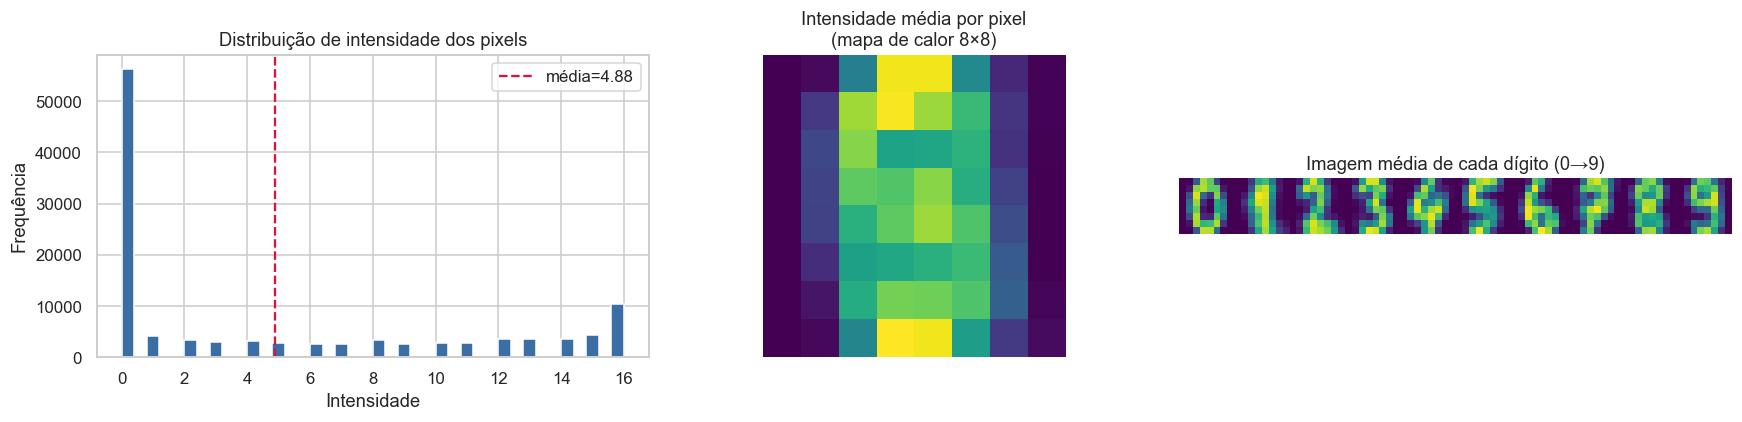

Pares de features com |correlação| > 0,90: -32
→ Redundância alta entre pixels vizinhos: PCA será muito eficaz aqui.


In [5]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

# (1) Distribuição global de intensidade
axes[0].hist(X_raw.ravel(), bins=40, color="#3b6ea5", edgecolor="white")
axes[0].set_title("Distribuição de intensidade dos pixels")
axes[0].set_xlabel("Intensidade"); axes[0].set_ylabel("Frequência")
axes[0].axvline(X_raw.mean(), color="crimson", ls="--", label=f"média={X_raw.mean():.2f}")
axes[0].legend()

# (2) Intensidade média por pixel (o "dígito médio")
axes[1].imshow(X_raw.mean(axis=0).reshape(8, 8), cmap="viridis")
axes[1].set_title("Intensidade média por pixel\n(mapa de calor 8×8)")
axes[1].axis("off")

# (3) Imagem média por classe real — mostra onde está o sinal
media_por_classe = np.array([X_raw[y_true == d].mean(axis=0) for d in range(10)])
grid = media_por_classe.reshape(10, 8, 8).transpose(1, 0, 2).reshape(8, 80)
axes[2].imshow(grid, cmap="viridis")
axes[2].set_title("Imagem média de cada dígito (0→9)")
axes[2].axis("off")

plt.tight_layout(); plt.show()

# Correlação entre features
corr = df.iloc[:, :64].corr().values
pares_altos = (np.abs(corr) > 0.9).sum() / 2 - 64   # descontando a diagonal
print(f"Pares de features com |correlação| > 0,90: {int(pares_altos)}")
print("→ Redundância alta entre pixels vizinhos: PCA será muito eficaz aqui.")

Componentes p/ 90% da variância: 31 de 64
Componentes p/ 95% da variância: 40 de 64
Redução de dimensionalidade    : 52%


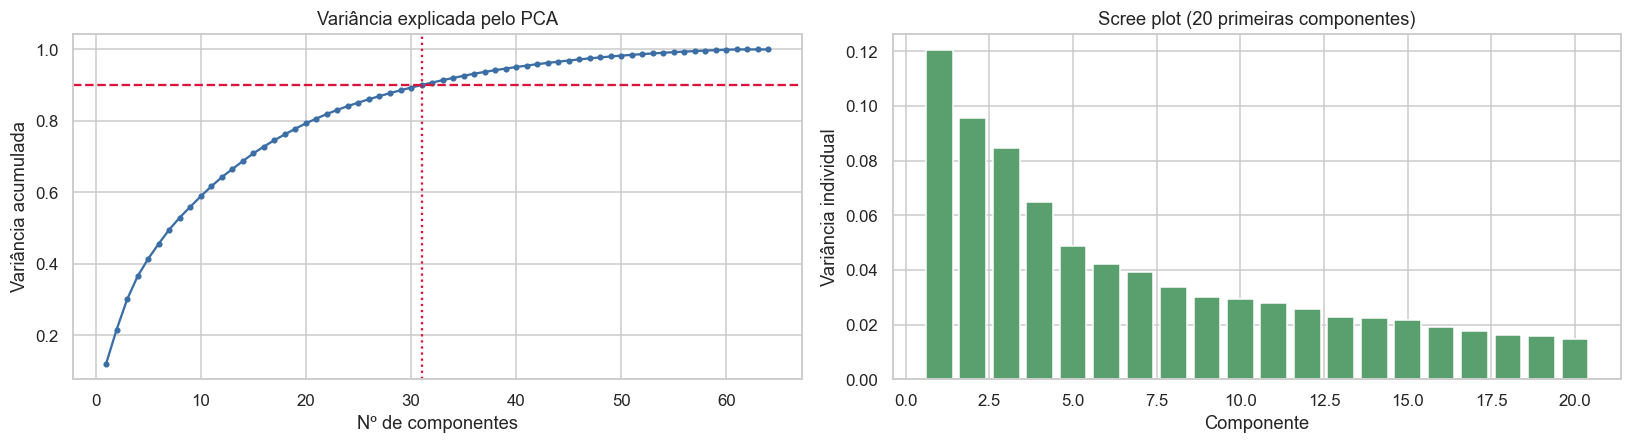


X_pca: (1797, 31)  |  X_pca10: (1797, 10)
Feature mais discriminante (PC1) explica 12.0% da variância.


In [6]:
# (1) Padronização — obrigatória antes de qualquer métrica de distância
scaler  = StandardScaler()
X_std   = scaler.fit_transform(X_raw)

# (2) PCA mantendo 90% da variância
pca_full = PCA(random_state=SEED).fit(X_std)
var_acum = np.cumsum(pca_full.explained_variance_ratio_)

n90 = int(np.argmax(var_acum >= 0.90) + 1)
n95 = int(np.argmax(var_acum >= 0.95) + 1)
print(f"Componentes p/ 90% da variância: {n90} de 64")
print(f"Componentes p/ 95% da variância: {n95} de 64")
print(f"Redução de dimensionalidade    : {(1 - n90/64):.0%}")

pca90 = PCA(n_components=n90, random_state=SEED)
X_pca = pca90.fit_transform(X_std)

# Espaço reduzido adicional para algoritmos de densidade (distâncias mais estáveis)
X_pca10 = X_pca[:, :10]

fig, axes = plt.subplots(1, 2, figsize=(15, 4.2))

axes[0].plot(range(1, 65), var_acum, marker="o", ms=3, color="#3b6ea5")
axes[0].axhline(0.90, color="crimson", ls="--")
axes[0].axvline(n90, color="crimson", ls=":")
axes[0].set_xlabel("Nº de componentes"); axes[0].set_ylabel("Variância acumulada")
axes[0].set_title("Variância explicada pelo PCA")

axes[1].bar(range(1, 21), pca_full.explained_variance_ratio_[:20], color="#5aa06e")
axes[1].set_xlabel("Componente"); axes[1].set_ylabel("Variância individual")
axes[1].set_title("Scree plot (20 primeiras componentes)")

plt.tight_layout(); plt.show()

print(f"\nX_pca: {X_pca.shape}  |  X_pca10: {X_pca10.shape}")
print(f"Feature mais discriminante (PC1) explica {pca_full.explained_variance_ratio_[0]:.1%} da variância.")

## 6. K-Means a fundo

O algoritmo mais usado da área — e o mais mal utilizado. Entenda o mecanismo antes
de usar.

### O algoritmo (algoritmo de Lloyd, 1957)

1. Escolha $k$ centróides iniciais (K-Means++ faz isso de forma inteligente,
   escolhendo pontos distantes entre si).
2. **Atribuição:** cada ponto vai para o centróide mais próximo.
3. **Atualização:** cada centróide vira a média dos pontos atribuídos a ele.
4. Repita 2–3 até convergir (centróides não mudam mais).

### A função objetivo

$$J = \sum_{i=1}^{n} \sum_{k=1}^{K} \mathbb{1}[x_i \in C_k] \cdot \|x_i - \mu_k\|^2$$

Essa é a **inércia** (inertia). O K-Means minimiza $J$ — e essa formulação carrega
todas as suas premissas.

### As quatro premissas escondidas na fórmula

| Premissa | Consequência quando violada |
|---|---|
| Clusters **convexos e esféricos** | Falsos agrupamentos em formas alongadas ou em "meia-lua" |
| Clusters de **tamanho similar** | Clusters pequenos são engolidos pelos grandes |
| **Variância similar** entre clusters | Um cluster difuso domina a fronteira dos demais |
| Todos os pontos **pertencem** a um cluster | Outliers recebem um cluster só para eles |

Além disso, K-Means **não detecta ruído** e **exige informar $k$**.

### Como escolher k

- **Elbow method:** plote a inércia × $k$ e procure o "cotovelo". Heurística, nem
  sempre claro.
- **Silhouette por $k$:** mais confiável que o elbow. É o critério que usaremos.
- **Conhecimento de domínio:** se o negócio espera 10 grupos, valide 10.

### Por que nunca inicializar aleatoriamente

Inicialização aleatória faz o K-Means cair em mínimos locais ruins. **K-Means++**
espalha os centróides iniciais com probabilidade proporcional à distância² — e é o
padrão do scikit-learn com `n_init=10`.

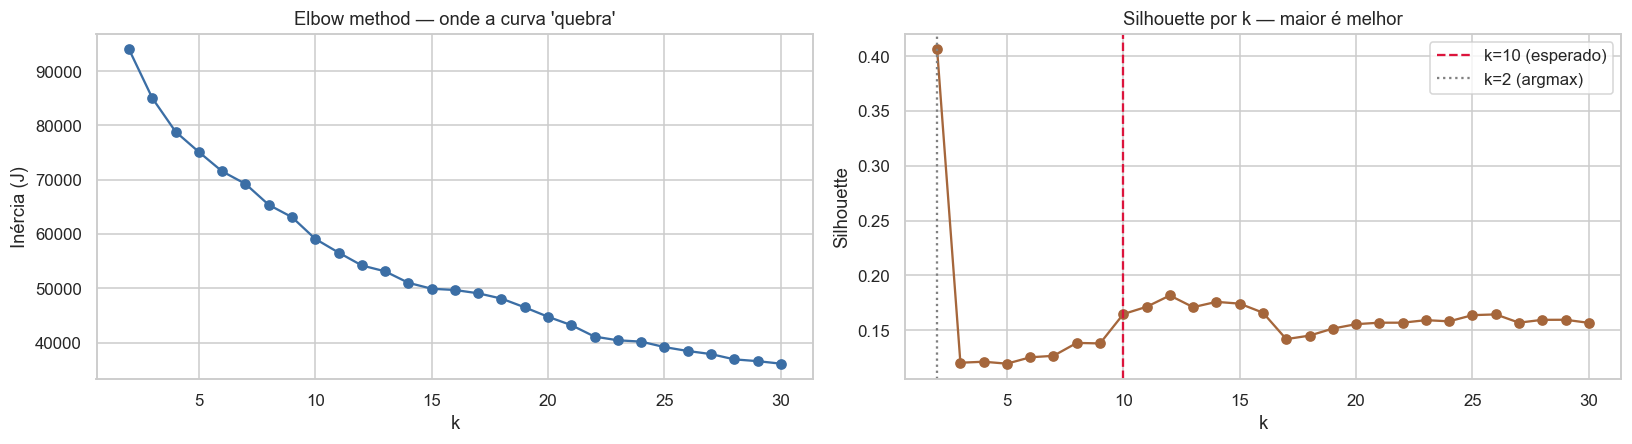

k ótimo pela Silhouette : 2
Silhouette em k=2     : 0.4062
Silhouette em k=10     : 0.1648
Delta (k=10 − ótimo)  : -0.2414

O ótimo de silhouette (k=2) se separa do k=10 por margem relevante — vale investigar o que o k escolhido perde.


In [7]:
K_ALVO  = 10
ks      = list(range(2, 31))

inercias, silhouetas = [], []          # <- reset DENTRO da célula do loop

with parallel_backend("threading"):
    for k in ks:
        km  = KMeans(n_clusters=k, n_init="auto", random_state=SEED)
        lab = km.fit_predict(X_pca)
        inercias.append(km.inertia_)
        silhouetas.append(silhouette_score(X_pca, lab,
                                           sample_size=1500,
                                           random_state=SEED))

# --- trava de integridade: falha alto e claro se algo desalinhar 
assert len(ks) == len(inercias) == len(silhouetas), (
    f"descompasso de tamanho — ks={len(ks)}, "
    f"inercias={len(inercias)}, silhouetas={len(silhouetas)}"
)

# --- índices resolvidos por valor de k, com o range de índices explícito
i_otimo   = max(range(len(ks)), key=lambda i: silhouetas[i])
k_sil     = ks[i_otimo]
sil_otimo = silhouetas[i_otimo]
sil_alvo  = silhouetas[ks.index(K_ALVO)]

fig, axes = plt.subplots(1, 2, figsize=(15, 4.2))

axes[0].plot(ks, inercias, marker="o", color="#3b6ea5")
axes[0].set_xlabel("k"); axes[0].set_ylabel("Inércia (J)")
axes[0].set_title("Elbow method — onde a curva 'quebra'")

axes[1].plot(ks, silhouetas, marker="o", color="#a5663b")
axes[1].set_xlabel("k"); axes[1].set_ylabel("Silhouette")
axes[1].axvline(K_ALVO, color="crimson", ls="--", label=f"k={K_ALVO} (esperado)")
axes[1].axvline(k_sil,  color="gray",    ls=":",  label=f"k={k_sil} (argmax)")
axes[1].legend(); axes[1].set_title("Silhouette por k — maior é melhor")

plt.tight_layout(); plt.show()

print(f"k ótimo pela Silhouette : {k_sil}")
print(f"Silhouette em k={k_sil}     : {sil_otimo:.4f}")
print(f"Silhouette em k={K_ALVO}     : {sil_alvo:.4f}")
print(f"Delta (k={K_ALVO} − ótimo)  : {sil_alvo - sil_otimo:+.4f}")

if k_sil == ks[-1]:
    print(f"\nATENÇÃO: o máximo caiu na borda da grade (k={k_sil}). "
          f"Estenda ks para além de {ks[-1]} antes de decidir — "
          "a métrica ainda pode estar subindo.")
elif abs(sil_alvo - sil_otimo) < 0.02:
    print(f"\nNota: a diferença entre k={K_ALVO} ({sil_alvo:.4f}) e o ótimo "
          f"k={k_sil} ({sil_otimo:.4f}) é pequena. O argmax da silhouette "
          "não discrimina com confiança neste intervalo.")
else:
    print(f"\nO ótimo de silhouette (k={k_sil}) se separa do k={K_ALVO} "
          "por margem relevante — vale investigar o que o k escolhido perde.")

                            Valor
Modelo             K-Means (k=10)
Clusters                       10
Ruído (%)                     0.0
Silhouette                 0.1733
Davies-Bouldin             1.7231
Calinski-Harabasz           135.3
ARI                        0.4677
NMI                        0.6204
Tempo (s)                    None


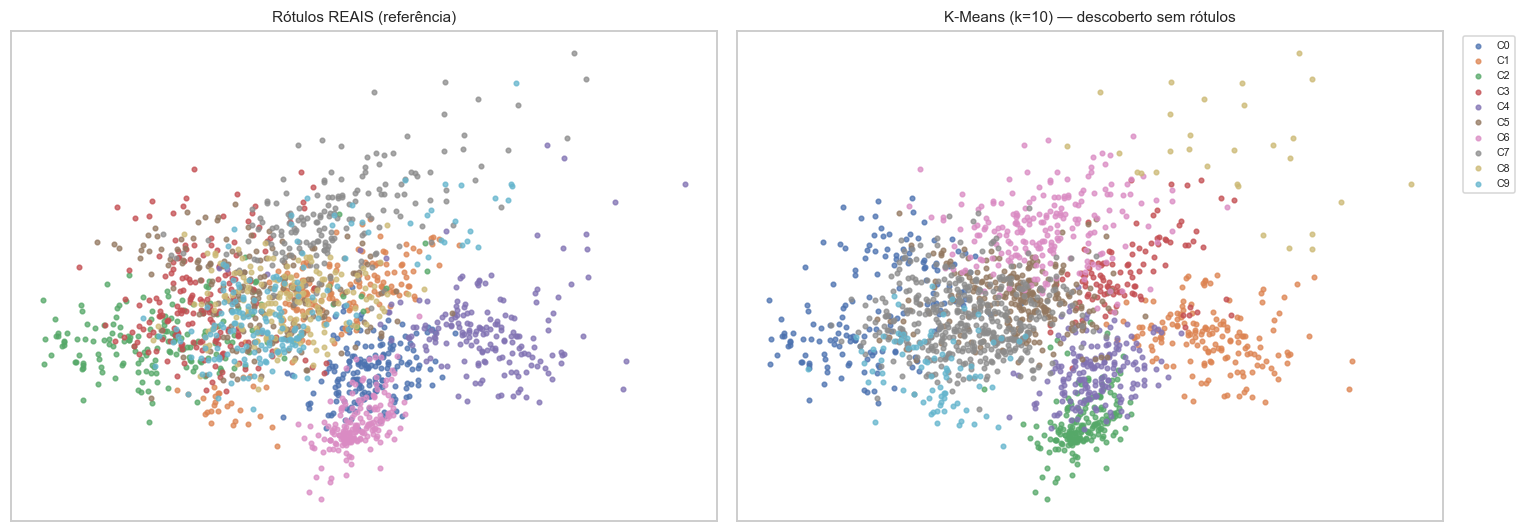


Tamanho de cada cluster:
count     10.0
mean     179.7
std      108.8
min       29.0
25%      119.5
50%      169.0
75%      207.8
max      428.0

Menor cluster: 29 | Maior cluster: 428


In [8]:
K_FINAL = 10   # justificado pelo domínio + elbow + silhouette

km_final = KMeans(n_clusters=K_FINAL, n_init=20, random_state=SEED)
labels_km = km_final.fit_predict(X_pca)

res_km = avaliar_modelo("K-Means (k=10)", labels_km, X_pca, y_true)
print(pd.DataFrame([res_km]).T.rename(columns={0: "Valor"}))

# Visualização no espaço PCA 2D
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

plot_2d(X_pca[:, :2], y_true, "Rótulos REAIS (referência)", ax=axes[0])
plot_2d(X_pca[:, :2], labels_km, "K-Means (k=10) — descoberto sem rótulos", ax=axes[1])
axes[1].legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=7, ncol=1)

plt.tight_layout(); plt.show()

# Tamanho dos clusters
tam = pd.Series(labels_km).value_counts().sort_index()
print("\nTamanho de cada cluster:")
print(tam.describe().round(1).to_string())
print(f"\nMenor cluster: {tam.min()} | Maior cluster: {tam.max()}")

In [9]:
from IPython.display import Markdown, display
import pandas as pd

def gerar_markdown(prefixo="df_"):
    nomes = sorted(
        k for k, v in globals().items()
        if k.startswith(prefixo) and isinstance(v, pd.DataFrame)
    )

    if not nomes:
        return f"_Nenhum DataFrame com prefixo `{prefixo}` encontrado._"

    total_registros = sum(globals()[n].shape[0] for n in nomes)

    blocos = ["# Resumo dos arquivos carregados\n"]
    blocos.append(f"**Arquivos processados:** {len(nomes)}  ")
    blocos.append(f"**Total de registros:** {total_registros:,}".replace(",", ".") + "\n")

    for nome in nomes:
        df = globals()[nome]
        nulos = int(df.isna().sum().sum())

        blocos.append(f"## `{nome}`\n")
        blocos.append(f"- **Linhas:** {df.shape[0]}")
        blocos.append(f"- **Colunas:** {df.shape[1]}")
        blocos.append(f"- **Valores ausentes:** {nulos}\n")

        meta = pd.DataFrame({
            "Coluna": list(df.columns),
            "Tipo": [str(t) for t in df.dtypes],
            "Preenchidos": df.notna().sum().tolist(),
        })
        blocos.append(meta.to_markdown(index=False))
        blocos.append("\n**Primeiras 5 linhas:**\n")
        blocos.append(df.head(5).to_markdown(index=False))
        blocos.append("")

    return "\n".join(blocos)

display(Markdown(gerar_markdown()))

_Nenhum DataFrame com prefixo `df_` encontrado._

In [10]:
ks

[2,
 3,
 4,
 5,
 6,
 7,
 8,
 9,
 10,
 11,
 12,
 13,
 14,
 15,
 16,
 17,
 18,
 19,
 20,
 21,
 22,
 23,
 24,
 25,
 26,
 27,
 28,
 29,
 30]

In [11]:
silhouetas

[0.4062039546706075,
 0.12040116161966377,
 0.12131494674426832,
 0.1195461007571909,
 0.1253611054192163,
 0.12670166048775852,
 0.13847615292655033,
 0.13802413395233207,
 0.1647896475131925,
 0.171420790488415,
 0.18175673645053203,
 0.171089596148501,
 0.1759402240320061,
 0.17430975412203112,
 0.16605068927222433,
 0.1419372814057708,
 0.14513483455690535,
 0.1515605093450219,
 0.15557801402138652,
 0.15692719163157973,
 0.15692719163157973,
 0.1592350796073875,
 0.15817552887502587,
 0.16380313794736223,
 0.16449300229649294,
 0.15694837875973572,
 0.15953799390545212,
 0.15959694022924784,
 0.15677594508230772]

In [12]:
inercias

[93992.31242718677,
 85016.57064214107,
 78831.4927239739,
 75103.25524604767,
 71532.22933584676,
 69232.66739402666,
 65370.16164026745,
 63100.02309853343,
 59094.80557069964,
 56577.16045709085,
 54204.59496384587,
 53117.445917467085,
 51008.43004795805,
 49912.108701229634,
 49681.55614945128,
 49074.195900632476,
 48098.09600033608,
 46486.07912915534,
 44749.06138947222,
 43207.821164468434,
 41095.45303463719,
 40415.08499464816,
 40170.561979760445,
 39166.62652308269,
 38445.88209012698,
 37875.35781159646,
 36904.06584671011,
 36574.27292512225,
 36109.83144638912]